# 种植模块：Gurobi MILP 求解器

本 notebook 实现 `planting/docs/种植模块_最优化问题与约束_审核稿.md` 中的独立种植模型。规划期为 Year 1 的 112 天，目标为最大化第 112 天日末现金。

建模顺序：读取日事件数据 → 创建变量 → 按审核稿编号添加约束 → 求解 → 审计解。

## 0. 环境与许可证

需要 Python 3、`pandas` 和已授权的 `gurobipy`。首次运行可在终端执行 `python -m pip install gurobipy`；随后按 Gurobi 的 academic / WLS / 本地许可证方式配置。若导入失败，下一个代码单元会给出明确提示。

In [1]:
from pathlib import Path
import pandas as pd

try:
    import gurobipy as gp
    from gurobipy import GRB
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        '未找到 gurobipy。请先运行：python -m pip install gurobipy；并配置有效 Gurobi 许可证。'
    ) from exc

# Notebook 可从项目根目录或 planting/notebooks/ 目录启动。
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
PROJECT_ROOT = next((p for p in candidates if (p / 'planting' / 'data').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('找不到项目根目录：应包含 planting/data/。')

PLANTING_DATA = PROJECT_ROOT / 'planting' / 'data'
SHARED_DATA = PROJECT_ROOT / 'shared' / 'data'
print(f'Project root: {PROJECT_ROOT}')


Project root: /Users/zoukaiyun/NUS/DBA5103/ProjectImplementation


## 1. 读取输入与构造参数

`crop_daily_events.csv` 是收获、浇水、最终土地释放和每格收入的唯一日事件来源。工具每格系数与升级现金成本均以 `planting_tool_catalog.csv` 为主。

In [2]:
calendar = pd.read_csv(PLANTING_DATA / 'crop_planting_calendar.csv')
events = pd.read_csv(PLANTING_DATA / 'crop_daily_events.csv')
crops = pd.read_csv(PLANTING_DATA / 'crops.csv')
tools = pd.read_csv(PLANTING_DATA / 'planting_tool_catalog.csv')
global_parameters = pd.read_csv(SHARED_DATA / 'global_parameters.csv')

def global_value(parameter_id, cast=float):
    value = global_parameters.loc[global_parameters.parameter_id.eq(parameter_id), 'value'].iloc[0]
    return cast(value)

T = list(range(1, 113))
C = sorted(calendar.crop_key.unique())
J = ['H', 'W']                 # H = Hoe; W = Watering Can
K = [0, 1, 2, 3]              # Basic, Copper, Steel, Gold
UPGRADE_K = [1, 2, 3]
tier_name = {0: 'Basic', 1: 'Copper', 2: 'Steel', 3: 'Gold'}
tool_name = {'H': 'Hoe', 'W': 'Watering Can'}

# pandas 可能把 CSV 的 true/false 读为 bool，统一转换，避免把所有 A[c,t] 误判为 0。
def as_bool(value):
    return str(value).strip().lower() == 'true'

# A[c,t] 和种子价格 p[c]。crops.csv 的季节重复行对同一物理种子价格相同。
A = {(r.crop_key, int(r.plant_day)): int(as_bool(r.plant_allowed_A_ct))
     for r in calendar.itertuples(index=False)}
seed_price_by_id = crops.groupby('seed_id').seed_price_g.first().to_dict()
seed_id_by_crop = {r.crop_key: int(r.seed_id) for r in calendar.itertuples(index=False)}
p = {c: float(seed_price_by_id[seed_id_by_crop[c]]) for c in C}
crop_name = calendar.groupby('crop_key').crop_name.first().to_dict()

# 日事件参数 h, f, w_need, r；没有事件的组合默认取 0。
event_key = ['crop_key', 'plant_day', 'calendar_day']
event_lookup = events.set_index(event_key)
def event_value(c, s, t, column, cast=float):
    key = (c, s, t)
    if key not in event_lookup.index:
        return cast(0)
    return cast(event_lookup.loc[key, column])

h = {(c, s, t): event_value(c, s, t, 'is_harvest', lambda v: int(as_bool(v)))
     for c in C for s in T for t in T if s <= t}
f = {(c, s, t): event_value(c, s, t, 'releases_land', lambda v: int(as_bool(v)))
     for c in C for s in T for t in T if s <= t}
w_need = {(c, s, t): event_value(c, s, t, 'needs_water', lambda v: int(as_bool(v)))
          for c in C for s in T for t in T if s <= t}
revenue = {(c, s, t): event_value(c, s, t, 'base_revenue_g_per_tile_harvest', float)
           for c in C for s in T for t in T if s <= t}

# 工具目录参数：按工具类型和等级取每格时间、体力及升级现金等价成本。
tool_row = tools.set_index(['tool_type', 'tier'])
tau = {(j, k): float(tool_row.loc[(tool_name[j], tier_name[k]), 'time_game_minutes_per_unit'])
       for j in J for k in K}
energy = {(j, k): float(tool_row.loc[(tool_name[j], tier_name[k]), 'energy_per_unit'])
          for j in J for k in K}
kappa = {k: float(tool_row.loc[('Watering Can', tier_name[k]), 'upgrade_cash_equivalent_cost_g'])
         for k in UPGRADE_K}

TIME_LIMIT = global_value('daily_time_limit_game_minutes')
ENERGY_LIMIT = global_value('daily_energy_limit')
INITIAL_CASH = global_value('initial_gold_g')
DELTA = {t: int(t in {1, 29, 57, 85}) for t in T}
M_L = M_W = int(TIME_LIMIT // 1.4)  # 642：安全日度作业格数上限
X_UB = int(TIME_LIMIT // (1.4 + 1.4))  # 321：新种的播种+浇水时间上限
assert M_L == M_W == 642 and X_UB == 321


## 2. 创建变量

变量命名与审核稿一致：`x, L, S_land, H, W, F, U, S_tool, D, Z, till, water, B`。特别地，`S_land` 是空闲耕地，而 `S_tool` 是工具等级状态，避免符号冲突。

In [3]:
model = gp.Model('stardew_planting_milp')
model.ModelSense = GRB.MAXIMIZE

# 3.1 作物、土地与由日事件决定的派生量。
x = model.addVars(C, T, vtype=GRB.INTEGER, lb=0, ub=X_UB, name='x')
L = model.addVars(T, vtype=GRB.INTEGER, lb=0, name='L')
S_land = model.addVars(T, vtype=GRB.INTEGER, lb=0, name='S_land')
H = model.addVars(C, T, vtype=GRB.INTEGER, lb=0, name='H')
W = model.addVars(T, vtype=GRB.INTEGER, lb=0, name='W')
F = model.addVars(T, vtype=GRB.INTEGER, lb=0, name='F')

# 3.2 工具升级、等级状态、服务期、实际可用性和作业分配。
U = model.addVars(J, UPGRADE_K, T, vtype=GRB.BINARY, name='U')
S_tool = model.addVars(J, K, T, vtype=GRB.BINARY, name='S_tool')
D = model.addVars(J, T, vtype=GRB.BINARY, name='D')
Z = model.addVars(J, K, T, vtype=GRB.BINARY, name='Z')
till = model.addVars(K, T, vtype=GRB.INTEGER, lb=0, name='till')
water = model.addVars(K, T, vtype=GRB.INTEGER, lb=0, name='water')

# 3.3 现金与资源派生量。B[t] 是 t 日末现金，B[0] 是规划开始时现金。
B = model.addVars(range(113), lb=0, name='B')
crop_revenue = model.addVars(T, lb=0, name='CropRevenue')
seed_cost = model.addVars(T, lb=0, name='SeedCost')
upgrade_cost = model.addVars(T, lb=0, name='UpgradeCost')
time_used = model.addVars(T, lb=0, name='TimeUsed')
energy_used = model.addVars(T, lb=0, name='EnergyUsed')


Set parameter Username
Set parameter LicenseID to value 2852968
Academic license - for non-commercial use only - expires 2027-08-12


## 3. 数学模型：约束清单

令 $t,s\in\mathcal T=\{1,\ldots,112\}$、$c\in\mathcal C$、$j\in\{H,W\}$、$k\in\{0,1,2,3\}$，其中 $U^j_{k,t}$ 仅定义于 $k=1,2,3$。以下 $h,f,w^{need},r,A,\tau,e,\kappa,\delta$ 均为预先读取的数据参数。

### 符号、Notebook 名称与已确认文档对照

本节对应 planting/docs/种植模块_最优化问题与约束_审核稿.md（下称“审核稿”）。代码中的 S_land 对应审核稿的 $S_t$，S_tool 对应审核稿的 $S^j_{k,t}$，以避免两个 $S$ 混淆。

| 数学符号 | Notebook 名称 | 含义 | 审核稿条款 |
| --- | --- | --- | --- |
| $x_{c,t}$ | x[c,t] | 当日新种的作物 $c$ 格数 | §3.1 |
| $L_t,S_t,H_{c,t},W_t,F_t$ | L, S_land, H, W, F | 新整地、日末空闲地、收获、浇水需求、最终释放土地 | §3.1 |
| $U^j_{k,t}$ | U[j,k,t] | 日初交付工具 $j$ 升至目标等级 $k$ | §3.2 |
| $S^j_{k,t},D^j_t,Z^j_{k,t}$ | S_tool, D, Z | 工具等级状态、服务期、实际可用性 | §3.2 |
| $l_{k,t},w_{k,t}$ | till[k,t], water[k,t] | 分别由等级 $k$ 锄头／水壶完成的格数 | §3.2 |
| $B_t$ | B[t] | 第 $t$ 日日末现金；B[0] 是 Day 1 日初现金 | §3.3 |
| $CropRevenue_t,SeedCost_t,UpgradeCost_t$ | crop_revenue, seed_cost, upgrade_cost | 日末作物收入、日初种子支出、日初升级支出 | §3.3、§7 |
| $T^{crop}_t,E^{crop}_t$ | time_used, energy_used | 种植模块日度时间与体力使用量 | §3.3、§6 |

| 固定参数 | Notebook 名称／来源 | 用途 | 审核稿条款 |
| --- | --- | --- | --- |
| $A_{c,t},h_{c,s,t},f_{c,s,t},w^{need}_{c,s,t},r_{c,s,t}$ | calendar、events 生成的字典 | 新种植许可与每日批次事件 | §2、§4.1–§4.2 |
| $p_c,\tau^j_k,e^j_k,\kappa_k$ | crops.csv、planting_tool_catalog.csv | 种子价、每格时间／体力、升级成本 | §2、§6、§7 |
| $\delta_t$ | DELTA[t] | 季首日空闲地清零指示 | §4.3 |
| $M_L,M_W,321$ | M_L, M_W, X_UB | 作业量及新种植的安全上界 | §4.1、§6 |

### 变量域与适用范围（审核稿 §3）

$$x_{c,t},L_t,S_t,H_{c,t},W_t,F_t,l_{k,t},w_{k,t}\in\mathbb Z_{\ge0}$$

$$U^j_{k,t},S^j_{k,t},D^j_t,Z^j_{k,t}\in\{0,1\},\qquad B_t,CropRevenue_t,SeedCost_t,UpgradeCost_t,T^{crop}_t,E^{crop}_t\in\mathbb R_{\ge0}$$

### 作物、事件与土地

**审核稿 §4.1｜新种植许可：** 不允许在不可种日期新种。

$$0 \le x_{c,t} \le 321A_{c,t},\qquad \forall c\in\mathcal C,\ t\in\mathcal T$$

**审核稿 §4.2｜收获事件：** 每日收获量由全部历史批次的固定事件决定。

$$H_{c,t}=\sum_{s\le t}h_{c,s,t}x_{c,s},\qquad \forall c,t$$

**审核稿 §4.2｜土地释放事件：** 只有最终收获才释放土地。

$$F_t=\sum_{c\in\mathcal C}\sum_{s\le t}f_{c,s,t}x_{c,s},\qquad \forall t$$

**审核稿 §4.2｜浇水需求事件：** 当日需浇水量由所有在地批次汇总。

$$W_t=\sum_{c\in\mathcal C}\sum_{s\le t}w^{need}_{c,s,t}x_{c,s},\qquad \forall t$$

**审核稿 §4.2｜收获收入事件：** 每格收入已包含基础产量与普通售价。

$$CropRevenue_t=\sum_{c\in\mathcal C}\sum_{s\le t}r_{c,s,t}x_{c,s},\qquad \forall t$$

**审核稿 §4.3｜空闲耕地平衡：** 季首日仅清空上一季空闲耕地。

$$S_t=(1-\delta_t)S_{t-1}+L_t+F_t-\sum_{c\in\mathcal C}x_{c,t},\qquad \forall t$$

$$S_0=0,\qquad S_t\ge0,\qquad \forall t$$

### 工具状态、升级与可用性

**审核稿 §5.1｜初始状态：** 两把工具均从 Basic 开始。

$$S^j_{0,1}=1,\qquad \forall j\in\mathcal J$$

$$S^j_{k,1}=0,\qquad \forall j\in\mathcal J,\ k=1,2,3$$

**审核稿 §5.2｜当前精确等级：** 每一天每把工具恰有一个等级状态。

$$\sum_{k=0}^{3}S^j_{k,t}=1,\qquad \forall j,t$$

**审核稿 §5.2｜等级状态递推：** 第 $t$ 日交付的升级在第 $t+2$ 日生效。

$$S^j_{k,t}=S^j_{k,t-1}-U^j_{k+1,t-2}+U^j_{k,t-2},\qquad \forall j,k,\ t\ge2$$

**审核稿 §5.3｜顺序升级：** 只能由 $k-1$ 级升级至 $k$ 级。

$$U^j_{k,t}\le S^j_{k-1,t},\qquad \forall j,t,\ k=1,2,3$$

**审核稿 §5.3｜服务期状态：** 送修当天和次日均处于服务期。

$$D^j_t=\sum_{k=1}^{3}U^j_{k,t}+\sum_{k=1}^{3}U^j_{k,t-1},\qquad \forall j,t$$

**审核稿 §5.3｜同一工具不可重复送修。**

$$\sum_{k=1}^{3}U^j_{k,t}+\sum_{k=1}^{3}U^j_{k,t-1}\le1,\qquad \forall j,t$$

**审核稿 §5.3｜每日最多送修一把工具：** 服务期重叠仍按既定简化允许。

$$\sum_{j\in\{H,W\}}\sum_{k=1}^{3}U^j_{k,t}\le1,\qquad \forall t$$

**审核稿 §5.4｜实际可用性：** 正常日 $Z=S$；服务期所有等级均不可用。

$$Z^j_{k,t}\le S^j_{k,t},\qquad \forall j,k,t$$

$$Z^j_{k,t}\le1-D^j_t,\qquad \forall j,k,t$$

$$Z^j_{k,t}\ge S^j_{k,t}-D^j_t,\qquad \forall j,k,t$$

其中边界约定 $U^j_{0,t}=U^j_{4,t}=0$，以及所有 $t\le0$ 的 $U^j_{k,t}=0$。

### 整地、浇水、时间与体力

**审核稿 §6｜整地工具连接：** 新整地格必须由当日可用锄头等级完成。

$$\sum_{k=0}^{3}l_{k,t}=L_t,\qquad \forall t$$

$$l_{k,t}\le642Z^H_{k,t},\qquad \forall k,t$$

**审核稿 §6｜浇水工具连接：** 所有需浇水格必须由当日可用水壶等级完成。

$$\sum_{k=0}^{3}w_{k,t}=W_t,\qquad \forall t$$

$$w_{k,t}\le642Z^W_{k,t},\qquad \forall k,t$$

**审核稿 §6｜日度时间：** 整地、播种、浇水、收获合计不超过 900 分钟。

$$T^{crop}_t=\sum_{k=0}^{3}\tau^H_kl_{k,t}+1.4\sum_cx_{c,t}+\sum_{k=0}^{3}\tau^W_kw_{k,t}+1.4\sum_cH_{c,t},\qquad \forall t$$

$$T^{crop}_t\le900,\qquad \forall t$$

**审核稿 §6｜日度体力：** 仅整地与浇水使用体力，总量不超过 270。

$$E^{crop}_t=\sum_{k=0}^{3}e^H_kl_{k,t}+\sum_{k=0}^{3}e^W_kw_{k,t},\qquad \forall t$$

$$E^{crop}_t\le270,\qquad \forall t$$

### 现金与目标函数

**审核稿 §7｜种子支出。**

$$SeedCost_t=\sum_cp_cx_{c,t},\qquad \forall t$$

**审核稿 §7｜工具升级支出。**

$$UpgradeCost_t=\sum_{j\in\{H,W\}}\sum_{k=1}^{3}\kappa_kU^j_{k,t},\qquad \forall t$$

**审核稿 §7｜日初支付约束：** 当日收获收入不能用于当天购买。

$$B_{t-1}\ge SeedCost_t+UpgradeCost_t,\qquad \forall t$$

**审核稿 §7｜日末现金平衡与初始现金。**

$$B_t=B_{t-1}-SeedCost_t-UpgradeCost_t+CropRevenue_t,\qquad \forall t$$

$$B_0=500,\qquad B_t\ge0,\qquad \forall t$$

**审核稿 §8｜目标函数。**

$$\max\;B_{112}$$

## 4. 约束实现

以下代码块按上方公式和审核稿第 4–7 节分组。每组均附约束名称，便于使用 Gurobi IIS 或 LP 导出文件定位不可行原因。

In [4]:
# 审核稿 §4.1｜新种植许可：A[c,t]=0 时，x[c,t] 必为 0。
for c in C:
    for t in T:
        model.addConstr(x[c, t] <= X_UB * A[c, t], name=f'plant_allowed[{c},{t}]')

# 审核稿 §4.2｜日事件：收获、最终释放、浇水需求和收获收入都由历史批次决定。
for t in T:
    model.addConstrs((
        H[c, t] == gp.quicksum(h[c, s, t] * x[c, s] for s in T if s <= t)
        for c in C), name=f'harvest_event_day_{t}')
    model.addConstr(F[t] == gp.quicksum(f[c, s, t] * x[c, s] for c in C for s in T if s <= t),
                    name=f'land_release[{t}]')
    model.addConstr(W[t] == gp.quicksum(w_need[c, s, t] * x[c, s] for c in C for s in T if s <= t),
                    name=f'water_need[{t}]')
    model.addConstr(crop_revenue[t] == gp.quicksum(revenue[c, s, t] * x[c, s]
                                                  for c in C for s in T if s <= t),
                    name=f'crop_revenue[{t}]')

# 审核稿 §4.3｜空闲耕地平衡：季首日清空上一季的空闲地，但不影响在地跨季作物。
for t in T:
    previous_empty_land = 0 if t == 1 else S_land[t - 1]
    model.addConstr(S_land[t] == (1 - DELTA[t]) * previous_empty_land + L[t] + F[t]
                    - gp.quicksum(x[c, t] for c in C), name=f'land_balance[{t}]')

# 审核稿 §5.1–§5.3｜工具状态、顺序升级和两天服务期。
for j in J:
    model.addConstr(S_tool[j, 0, 1] == 1, name=f'initial_basic[{j}]')
    for k in UPGRADE_K:
        model.addConstr(S_tool[j, k, 1] == 0, name=f'initial_no_upgrade[{j},{k}]')
    for t in T:
        model.addConstr(gp.quicksum(S_tool[j, k, t] for k in K) == 1,
                        name=f'exact_tool_tier[{j},{t}]')
        for k in UPGRADE_K:
            model.addConstr(U[j, k, t] <= S_tool[j, k - 1, t],
                            name=f'sequential_upgrade[{j},{k},{t}]')
        u_today = gp.quicksum(U[j, k, t] for k in UPGRADE_K)
        u_yesterday = 0 if t == 1 else gp.quicksum(U[j, k, t - 1] for k in UPGRADE_K)
        model.addConstr(D[j, t] == u_today + u_yesterday, name=f'service_state[{j},{t}]')
        model.addConstr(u_today + u_yesterday <= 1, name=f'no_resubmit[{j},{t}]')
        if t >= 2:
            for k in K:
                leave_old = 0 if k == 3 or t == 2 else U[j, k + 1, t - 2]
                enter_new = 0 if k == 0 or t == 2 else U[j, k, t - 2]
                model.addConstr(S_tool[j, k, t] == S_tool[j, k, t - 1] - leave_old + enter_new,
                                name=f'tool_state_transition[{j},{k},{t}]')

# 审核稿 §5.3｜每日最多交付一把工具；服务期重叠在当前简化下允许。
for t in T:
    model.addConstr(gp.quicksum(U[j, k, t] for j in J for k in UPGRADE_K) <= 1,
                    name=f'one_tool_submission_per_day[{t}]')

# 审核稿 §5.4｜实际可用性：送修当天和次日的所有 Z 都为 0。
for j in J:
    for k in K:
        for t in T:
            model.addConstr(Z[j, k, t] <= S_tool[j, k, t], name=f'available_only_owned[{j},{k},{t}]')
            model.addConstr(Z[j, k, t] <= 1 - D[j, t], name=f'not_in_service[{j},{k},{t}]')
            model.addConstr(Z[j, k, t] >= S_tool[j, k, t] - D[j, t],
                            name=f'available_when_owned[{j},{k},{t}]')

# 审核稿 §6｜工具行动连接：所有整地和浇水需求都须由当天可用等级完成。
for t in T:
    model.addConstr(gp.quicksum(till[k, t] for k in K) == L[t], name=f'till_all_new_land[{t}]')
    model.addConstr(gp.quicksum(water[k, t] for k in K) == W[t], name=f'water_all_required[{t}]')
    for k in K:
        model.addConstr(till[k, t] <= M_L * Z['H', k, t], name=f'till_requires_hoe[{k},{t}]')
        model.addConstr(water[k, t] <= M_W * Z['W', k, t], name=f'water_requires_can[{k},{t}]')

    # 审核稿 §6｜时间与体力。播种、收获每格均为 1.4 分钟且不耗体力。
    model.addConstr(time_used[t] == gp.quicksum(tau['H', k] * till[k, t] for k in K)
                    + 1.4 * gp.quicksum(x[c, t] for c in C)
                    + gp.quicksum(tau['W', k] * water[k, t] for k in K)
                    + 1.4 * gp.quicksum(H[c, t] for c in C), name=f'time_accounting[{t}]')
    model.addConstr(energy_used[t] == gp.quicksum(energy['H', k] * till[k, t] for k in K)
                    + gp.quicksum(energy['W', k] * water[k, t] for k in K),
                    name=f'energy_accounting[{t}]')
    model.addConstr(time_used[t] <= TIME_LIMIT, name=f'time_limit[{t}]')
    model.addConstr(energy_used[t] <= ENERGY_LIMIT, name=f'energy_limit[{t}]')

# 审核稿 §7｜现金：日初必须先支付种子／升级；收获收入在日末进入 B[t]。
model.addConstr(B[0] == INITIAL_CASH, name='initial_cash')
for t in T:
    model.addConstr(seed_cost[t] == gp.quicksum(p[c] * x[c, t] for c in C), name=f'seed_cost[{t}]')
    model.addConstr(upgrade_cost[t] == gp.quicksum(kappa[k] * U[j, k, t]
                                                for j in J for k in UPGRADE_K),
                    name=f'upgrade_cost[{t}]')
    model.addConstr(B[t - 1] >= seed_cost[t] + upgrade_cost[t], name=f'cash_before_spending[{t}]')
    model.addConstr(B[t] == B[t - 1] - seed_cost[t] - upgrade_cost[t] + crop_revenue[t],
                    name=f'cash_balance[{t}]')

# 审核稿 §8｜目标：最大化 Day 112 日末现金。
model.setObjective(B[112], GRB.MAXIMIZE)
model.update()
print(f'Variables: {model.NumVars:,}; constraints: {model.NumConstrs:,}')


Variables: 11,201; constraints: 14,001


## 5. 求解、结果导出、现金图与可行性审计

求解后输出逐日资源表、种植汇总和关键约束余量，并写出每日决策 CSV 与日末现金图。若模型不可行，代码会导出 `planting_infeasible.ilp`，可在 Gurobi 中检查 IIS。

Set parameter MIPGap to value 0.001
Gurobi Optimizer version 13.0.2 build v13.0.2rc1 (mac64[arm] - Darwin 25.6.0 25G83)

CPU model: Apple M1 Pro
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Non-default parameters:
MIPGap  0.001

Optimize a model with 14001 rows, 11201 columns and 52210 nonzeros (Max)
Model fingerprint: 0x9a8aef2b
Model has 1 linear objective coefficients
Variable types: 673 continuous, 10528 integer (2688 binary)
Coefficient statistics:
  Matrix range     [1e-01, 1e+04]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 3e+02]
  RHS range        [1e+00, 9e+02]

Presolve removed 9408 rows and 7718 columns
Presolve time: 0.15s
Presolved: 4593 rows, 3483 columns, 25298 nonzeros
Variable types: 0 continuous, 3483 integer (2012 binary)

Root relaxation: objective 3.576101e+05, 3299 iterations, 0.13 seconds (0.15 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf

day,season_day,hoe_status,watering_can_status,new_tilled,plant_decision,watered,harvest_decision,upgrade_submitted,time_minutes,energy,cash_end_g
1,Spring 1,Basic,Basic,25,Parsnip × 25,25,-,-,105.0,75.00,0
2,Spring 2,Basic,Basic,0,-,25,-,-,35.0,25.00,0
3,Spring 3,Basic,Basic,0,-,25,-,-,35.0,25.00,0
4,Spring 4,Basic,Basic,17,-,25,-,-,58.8,59.00,0
5,Spring 5,Basic,Basic,0,-,0,Parsnip × 25,-,35.0,0.00,875
6,Spring 6,Basic,Basic,0,Parsnip × 41; Potato × 1,42,-,-,117.6,42.00,5
7,Spring 7,Basic,Basic,0,-,42,-,-,58.8,42.00,5
8,Spring 8,Basic,Basic,0,-,42,-,-,58.8,42.00,5
9,Spring 9,Basic,Basic,0,-,42,-,-,58.8,42.00,5
10,Spring 10,Basic,Basic,0,-,1,Parsnip × 41,-,58.8,1.00,"1,440"


每日决策已写出：/Users/zoukaiyun/NUS/DBA5103/ProjectImplementation/planting/outputs/full_resources/daily_decisions.csv


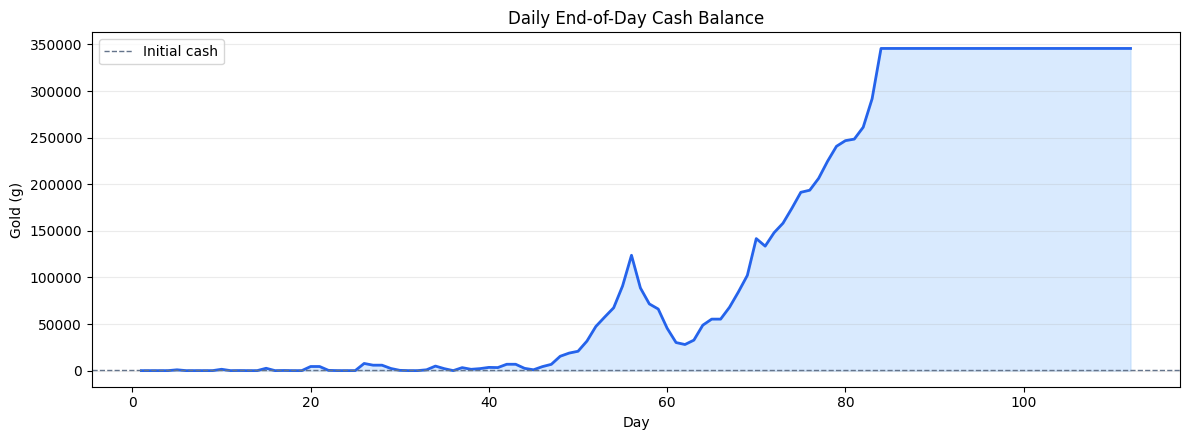

现金图已写出：/Users/zoukaiyun/NUS/DBA5103/ProjectImplementation/planting/outputs/full_resources/daily_cash_balance.png
按作物批次展开的种植决策：


crop_key,crop_name,plant_day,season_day,tiles
seed_472,Parsnip,1,Spring 1,25
seed_472,Parsnip,6,Spring 6,41
seed_475,Potato,6,Spring 6,1
seed_472,Parsnip,11,Spring 11,72
seed_472,Parsnip,13,Spring 13,4
seed_472,Parsnip,16,Spring 16,126
seed_472,Parsnip,18,Spring 18,7
seed_472,Parsnip,22,Spring 22,219
seed_472,Parsnip,23,Spring 23,13
seed_482,Hot Pepper,29,Summer 1,80


Audit passed: time, energy, cash non-negativity, and one-tool-per-day constraints hold.


In [5]:
model.Params.MIPGap = 0.001
model.optimize()

if model.Status == GRB.OPTIMAL or model.Status == GRB.TIME_LIMIT and model.SolCount > 0:
    print(f'Status: {model.Status}; objective (Day 112 cash): {B[112].X:,.2f}g')

    def season_label(t):
        seasons = ['Spring', 'Summer', 'Fall', 'Winter']
        return f'{seasons[(t - 1) // 28]} {(t - 1) % 28 + 1}'

    def crop_summary(values):
        parts = [f'{crop_name[c]} × {value:,.0f}' for c, value in values if value > 0.5]
        return '; '.join(parts) if parts else '-'

    def tool_status(j, t):
        if D[j, t].X > 0.5:
            return '送修中'
        active_tier = next(k for k in K if Z[j, k, t].X > 0.5)
        return tier_name[active_tier]

    daily_rows = []
    for t in T:
        submissions = [f'{tool_name[j]}->{tier_name[k]}' for j in J for k in UPGRADE_K if U[j, k, t].X > 0.5]
        daily_rows.append({
            'day': t, 'season_day': season_label(t),
            'hoe_status': tool_status('H', t), 'watering_can_status': tool_status('W', t),
            'new_tilled': L[t].X,
            'plant_decision': crop_summary([(c, x[c, t].X) for c in C]),
            'watered': W[t].X,
            'harvest_decision': crop_summary([(c, H[c, t].X) for c in C]),
            'released_land': F[t].X,
            'empty_land_end': S_land[t].X, 'seed_cost_g': seed_cost[t].X,
            'upgrade_cost_g': upgrade_cost[t].X, 'revenue_g': crop_revenue[t].X,
            'time_minutes': time_used[t].X, 'energy': energy_used[t].X,
            'cash_end_g': B[t].X, 'upgrade_submitted': ', '.join(submissions) or '-'
        })
    daily_solution = pd.DataFrame(daily_rows)
    daily_decisions = daily_solution[[
        'day', 'season_day', 'hoe_status', 'watering_can_status', 'new_tilled',
        'plant_decision', 'watered', 'harvest_decision', 'upgrade_submitted',
        'time_minutes', 'energy', 'cash_end_g'
    ]].copy()
    # 每一行就是一天的完整行动决策；隐藏 pandas 行索引，避免与 day 混淆。
    display(daily_decisions.style.hide(axis='index').format({
        'new_tilled': '{:,.0f}', 'watered': '{:,.0f}', 'time_minutes': '{:,.1f}',
        'energy': '{:,.2f}', 'cash_end_g': '{:,.0f}'
    }))

    # 导出一日一行的可交付决策表；UTF-8-SIG 便于直接用 Excel 打开中文。
    # 完整资源情景单独写入 full_resources，避免覆盖其他资源分配情景。
    OUTPUT_DIR = PROJECT_ROOT / 'planting' / 'outputs' / 'full_resources'
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    daily_csv = OUTPUT_DIR / 'daily_decisions.csv'
    daily_decisions.to_csv(daily_csv, index=False, encoding='utf-8-sig')
    print(f'每日决策已写出：{daily_csv}')

    # 日末现金变化图，同时在 notebook 显示并保存为 PNG。
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(daily_solution['day'], daily_solution['cash_end_g'], color='#2563EB', linewidth=2)
    ax.fill_between(daily_solution['day'], daily_solution['cash_end_g'], color='#93C5FD', alpha=0.35)
    ax.axhline(INITIAL_CASH, color='#64748B', linestyle='--', linewidth=1, label='Initial cash')
    ax.set(title='Daily End-of-Day Cash Balance', xlabel='Day', ylabel='Gold (g)')
    ax.grid(axis='y', alpha=0.25)
    ax.legend()
    fig.tight_layout()
    cash_plot = OUTPUT_DIR / 'daily_cash_balance.png'
    fig.savefig(cash_plot, dpi=160, bbox_inches='tight')
    plt.show()
    print(f'现金图已写出：{cash_plot}')

    planting_rows = [{'crop_key': c, 'crop_name': crop_name[c], 'plant_day': t,
                      'season_day': season_label(t), 'tiles': x[c, t].X}
                     for c in C for t in T if x[c, t].X > 0.5]
    if planting_rows:
        planting_plan = pd.DataFrame(planting_rows).sort_values(['plant_day', 'crop_key'])
        print('按作物批次展开的种植决策：')
        display(planting_plan.style.hide(axis='index').format({'tiles': '{:,.0f}'}))
        planting_plan.to_csv(OUTPUT_DIR / 'planting_batches.csv', index=False, encoding='utf-8-sig')
    else:
        print('最优解中没有种植决策；请检查 A[c,t]、现金和资源约束。')

    # 审计：检验日度上限、现金不为负、每日送修次数和工具可用性。
    assert daily_solution.time_minutes.max() <= TIME_LIMIT + 1e-6
    assert daily_solution.energy.max() <= ENERGY_LIMIT + 1e-6
    assert daily_solution.cash_end_g.min() >= -1e-6
    assert all(sum(U[j, k, t].X for j in J for k in UPGRADE_K) <= 1 + 1e-6 for t in T)
    print('Audit passed: time, energy, cash non-negativity, and one-tool-per-day constraints hold.')
else:
    print(f'No usable solution. Gurobi status: {model.Status}')
    if model.Status == GRB.INFEASIBLE:
        model.computeIIS()
        model.write('planting_infeasible.ilp')
        print('Wrote IIS to planting_infeasible.ilp for diagnosis.')
